# Train Card Strength Model

**Objectives:**
- Prepare the dataset for training by splitting and scaling features.
- Train an late fusion model.
- Evaluate model accuracy using MAE and RMSE metrics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from embeddings.mtg_dataset import MTGDataset
from embeddings.mtg_fusion_model import MTGFusionModel

In [2]:
INPUT_DATA_PATH = "../data/training/card_strength_input.parquet"
LABEL_DATA_PATH = "../data/training/card_strength_metric.xlsx"
OUTPUT_MODEL_PATH = "../models/card_strength_model.pth"
SEED = 1893
EPOCHS = 50
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
np.random.seed(SEED)
df_input = pd.read_parquet(INPUT_DATA_PATH)
df_label = pd.read_excel(LABEL_DATA_PATH)

cols_to_use = df_label.columns.difference(df_input.columns).tolist()
df = df_input.merge(df_label[cols_to_use + ["oracle_id"]], on="oracle_id", how="left")

print(f"Shape: {df.shape}")
df.head()

Shape: (29677, 805)


,oracle_id,name,card_faces,mana_cost,cmc,type_line,oracle_text,power,toughness,loyalty,...,bool_is_colorless,bool_is_modal,bool_is_transform,bool_is_saga,bool_is_class,inclusion,inclusion_rate,log_inclusion_rate,log_power_score,potential_decks
0,00037840-6089-42ec-8c5c-281f9f474504,"Nissa, Worldsoul Speaker",None,{3}{G},4.0,Legendary Creature — Elf Druid,"Landfall — Whenever a land you control enters,...",3,3,None,...,0,0,0,0,0,12512.0,0.004480,-2.348676,74.413949,2792563.0
1,0004ebd0-dfd6-4276-b4a6-de0003e94237,Static Orb,None,{3},3.0,Artifact,"As long as this artifact is untapped, players ...",None,None,None,...,1,0,0,0,0,23344.0,0.002853,-2.544718,72.291741,8182645.0
2,0006faf6-7a61-426c-9034-579f2cfcfa83,Sensory Deprivation,None,{U},1.0,Enchantment — Aura,Enchant creature\nEnchanted creature gets -3/-0.,None,None,None,...,0,0,0,0,0,216.0,0.000053,-4.272553,53.587475,4045825.0
3,0007c283-5b7a-4c00-9ca1-b455c8dff8c3,Road of Return,None,{G}{G},2.0,Sorcery,Choose one —\n• Return target permanent card f...,None,None,None,...,0,1,0,0,0,10214.0,0.002696,-2.569260,72.026074,3788399.0
4,000d5588-5a4c-434e-988d-396632ade42c,Storm Crow,None,{1}{U},2.0,Creature — Bird,Flying (This creature can't be blocked except ...,1,2,None,...,0,0,0,0,0,1582.0,0.000391,-3.407801,62.948650,4045825.0


## Data Filtering

Exclude most recent set (and every card that has been release since to avoid inaccuracies)

In [ ]:
# TODO: from all sets find the most recent (that has been released)
# -> filter all cards from that set and cards that are released after that (like secret lairs)

## Feature Preparation

In [6]:
embedding_cols = [col for col in df.columns if col.startswith('embed_')]
embedding_features = df[embedding_cols].values
boolean_cols = [col for col in df.columns if col.startswith('bool_')]
boolean_features = df[boolean_cols].values
numerical_cols = [col for col in df.columns if col.startswith('num_')]
numerical_features = df[numerical_cols].values

feature_cols = embedding_cols + numerical_cols + boolean_cols
target_col = 'log_power_score'

## Correlation Analysis

- Calculate Pearson correlation between features and the target power score.
- Plot the top positive and negative correlations to validate feature engineering.

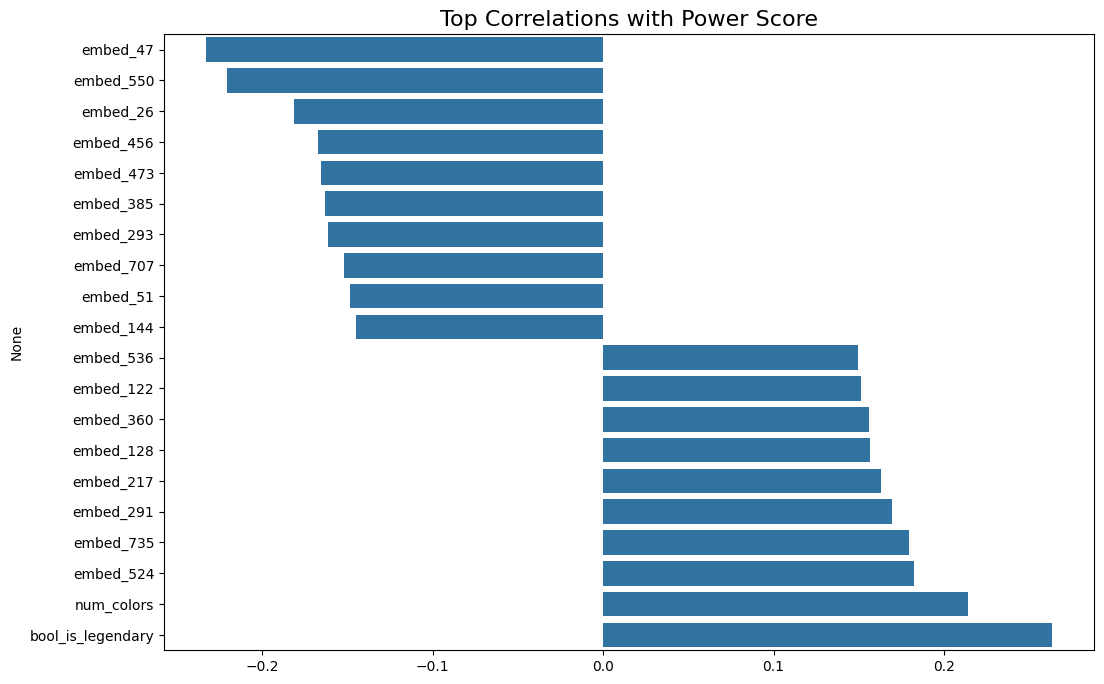

In [7]:
correlations = df[feature_cols + [target_col]].corr()[target_col].drop(target_col)
top_correlations = pd.concat([correlations.nsmallest(10), correlations.nlargest(10)]).sort_values()

plt.figure(figsize=(12, 8))
sns.barplot(x=top_correlations.values, y=top_correlations.index)
plt.title('Top Correlations with Power Score', fontsize=16)
plt.show()

## Data Splitting

- Split data into Training (60%), Validation (20%), and Test (20%) sets.
- Ensure stratification and reproducibility using the defined seed.

In [9]:
text_embeddings = df[embedding_cols].values
tabular_features = df[numerical_cols + boolean_cols].fillna(-1).values

# Scale numerical features (fill NaN with -1 as MTG values are mostly >=0)
tabular_features = df[numerical_cols + boolean_cols].fillna(-1).values
scaler = StandardScaler()
tabular_features = scaler.fit_transform(tabular_features)

targets = df[target_col].values

X_text_train_val, X_text_test, X_tab_train_val, X_tab_test, y_train_val, y_test = train_test_split(
    text_embeddings, tabular_features, targets, test_size=0.20, random_state=SEED
)

X_text_train, X_text_val, X_tab_train, X_tab_val, y_train, y_val = train_test_split(
    X_text_train_val, X_tab_train_val, y_train_val, test_size=0.25, random_state=SEED
)

print(f"Training data: {X_text_train.shape[0]} cards")
print(f"Validation data: {X_text_val.shape[0]} cards")
print(f"Test data: {X_text_test.shape[0]} cards")

Training data: 17805 cards
Validation data: 5936 cards
Test data: 5936 cards


## Train late fusion model

In [10]:
train_ds = MTGDataset(X_text_train, X_tab_train, y_train)
val_ds = MTGDataset(X_text_val, X_tab_val, y_val)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)

model = MTGFusionModel(
    text_dim=len(embedding_cols), 
    tabular_dim=tabular_features.shape[1]
).to(DEVICE)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.5)

# 5. Training Loop
best_loss = float('inf')

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for texts, tabs, labels in train_loader:
        texts, tabs, labels = texts.to(DEVICE), tabs.to(DEVICE), labels.to(DEVICE)
        
        optimizer.zero_grad()
        outputs = model(texts, tabs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * texts.size(0)
        
    train_loss /= len(train_loader.dataset)
    
    # Validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for texts, tabs, labels in val_loader:
            texts, tabs, labels = texts.to(DEVICE), tabs.to(DEVICE), labels.to(DEVICE)
            outputs = model(texts, tabs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * texts.size(0)
    
    val_loss /= len(val_loader.dataset)
    scheduler.step(val_loss)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
        
    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), "best_fusion_model.pth")
        
print(f"Training complete. Best Val Loss: {best_loss:.4f}")

Epoch 1/50 | Train Loss: nan | Val Loss: nan
Epoch 2/50 | Train Loss: nan | Val Loss: nan
Epoch 3/50 | Train Loss: nan | Val Loss: nan
Epoch 4/50 | Train Loss: nan | Val Loss: nan
Epoch 5/50 | Train Loss: nan | Val Loss: nan
Epoch 6/50 | Train Loss: nan | Val Loss: nan
Epoch 7/50 | Train Loss: nan | Val Loss: nan
Epoch 8/50 | Train Loss: nan | Val Loss: nan
Epoch 9/50 | Train Loss: nan | Val Loss: nan
Epoch 10/50 | Train Loss: nan | Val Loss: nan


KeyboardInterrupt: 

## Test model

In [ ]:
test_ds = MTGDataset(X_text_test, X_tab_test, y_test)
test_loader = DataLoader(test_ds, batch_size=64)

# TODO: do inference of test set and calculate regression metrics (MSE, MAE, variance, ...)